In [1]:
# Load the data and look at the first rows
import pandas as pd
train = pd.read_csv("Train (1).csv")
test = pd.read_csv("Test.csv")
train.head()

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0


In [2]:
# Check column types and missing values
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   str    
 1   zone                  3146 non-null   str    
 2   gender                3146 non-null   str    
 3   deathdate             3146 non-null   str    
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   str    
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), str(5)
memory usage: 556.2 KB


In [3]:
# Count how many rows are in each class of the target
print(train['is_climate_sensitive'].value_counts())
print(train['is_climate_sensitive'].value_counts(normalize=True))

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64
is_climate_sensitive
1    0.650668
0    0.349332
Name: proportion, dtype: float64


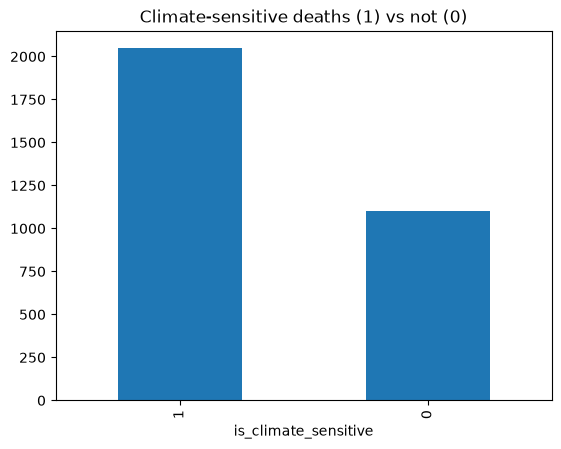

In [4]:
# Plot the target classes as a bar chart
import matplotlib.pyplot as plt
train['is_climate_sensitive'].value_counts().plot(kind='bar')
plt.title('Climate-sensitive deaths (1) vs not (0)')
plt.show()

**What it shows:** the number of deaths labelled climate-sensitive (1) and not (0).

**Pattern:** 2,047 deaths (65.1%) are climate-sensitive and 1,099 (34.9%) are not.

**Meaning:** the classes are moderately imbalanced. A model that always answered "climate-sensitive" would be right 65% of the time, so accuracy alone will not show whether a model has learned anything. F1 and ROC-AUC will be reported as well, and imbalance handling will be tested.

In [5]:
# Summary statistics of age
train['age'].describe()

count    3146.000000
mean       24.243484
std        31.428833
min         0.000000
25%         0.000000
50%         3.000000
75%        49.000000
max       110.000000
Name: age, dtype: float64

In [6]:
# Compare age between the two classes
train.groupby('is_climate_sensitive')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
is_climate_sensitive,,,,,,,,
0,1099.0,43.253867,33.198445,0.0,4.0,46.0,74.0,106.0
1,2047.0,14.037128,25.070645,0.0,0.0,1.0,16.5,110.0


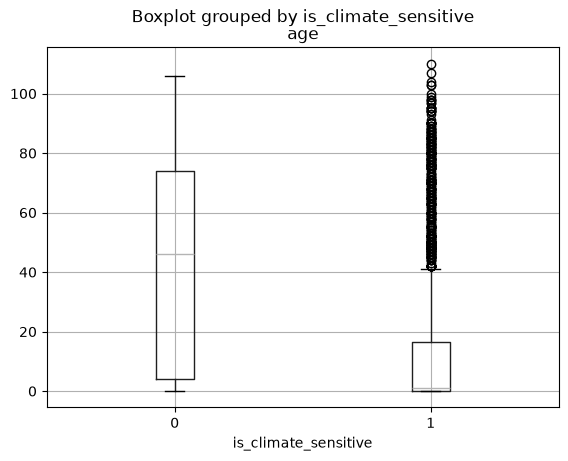

In [7]:
# Boxplot of age for each class
train.boxplot(column='age', by='is_climate_sensitive')
plt.show()

**What it shows:** the spread of age for each class. In each box, the line is the median, the box covers the middle half of the deaths, and the circles are unusually high values.

**Pattern:** for climate-sensitive deaths (1) the median age is 1 and the box runs only from 0 to about 16. For deaths that are not climate-sensitive (0) the median is 46 and the box runs from about 4 to 74, with whiskers up to about 106.

**Meaning:** climate-sensitive deaths are concentrated in infants and young children, while other deaths are spread across adult and older ages. The column of circles above age 41 on the right does not mean the data is wrong. Class 1 is so concentrated at young ages that older people in class 1 look unusual by comparison. They are real ages (the oldest is 110), so no rows are removed. This agrees with the age-group chart, and shows why age is expected to be the strongest predictor.

In [8]:
# How many rows have age 0, split by class
print((train['age'] == 0).groupby(train['is_climate_sensitive']).sum())

is_climate_sensitive
0    236
1    876
Name: age, dtype: int64


In [9]:
# Share of class 1 within each age group
train['age_group'] = pd.cut(train['age'], bins=[-1, 0, 5, 17, 40, 65, 120])
train.groupby('age_group')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
age_group,,
"(-1, 0]",1112,0.787770
"(0, 5]",644,0.919255
"(5, 17]",116,0.586207
"(17, 40]",369,0.528455
"(40, 65]",351,0.438746
"(65, 120]",554,0.292419


In [10]:
# Share of class 1 within each zone
train.groupby('zone')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
zone,,
Peri_urban,1174,0.640545
Rural,1972,0.656694


In [11]:
# Share of class 1 within each gender
train.groupby('gender')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
gender,,
Female,1501,0.671552
Male,1645,0.631611


In [12]:
# Find the 10 most common locations
top = train['location'].value_counts().head(10).index
top

Index(['Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda',
       'Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda',
       'Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda',
       'Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda',
       'Nawanzu, Iganga, Uganda',
       'Kabila, Kasonga, Kikuube, Western Region, Uganda',
       'Nawansinge, Iganga, Uganda', 'Wairama, Iganga, Uganda',
       'Nakigo Ii, Iganga, Uganda', 'Kasokoso South, Iganga, Uganda'],
      dtype='str', name='location')

In [13]:
# Keep only those rows, then compare class 1 share
small = train[train['location'].isin(top)]
small.groupby('location')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",211,0.639810
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",207,0.623188
"Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda",155,0.632258
"Kabila, Kasonga, Kikuube, Western Region, Uganda",128,0.648438
"Kasokoso South, Iganga, Uganda",114,0.701754
"Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda",158,0.639241
"Nakigo Ii, Iganga, Uganda",116,0.706897
"Nawansinge, Iganga, Uganda",120,0.658333
"Nawanzu, Iganga, Uganda",146,0.691781


In [14]:
# Number of different location names
train['location'].nunique()

39

In [15]:
# How many locations have fewer than 10 rows
counts = train['location'].value_counts()
print((counts < 10).sum())

3


In [16]:
# Check coordinates for the two Brac Uganda spellings
brac = train[train['location'].str.contains('Brac Uganda')]
brac.groupby('location')[['latitude', 'longitude']].nunique()

,latitude,longitude
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",1,1
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",1,1


In [17]:
# Show the coordinates of each Brac Uganda spelling
brac.groupby('location')[['latitude', 'longitude']].first()

,latitude,longitude
location,,
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda",0.608396,33.482668
"Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda",0.608396,33.482668


In [18]:
# Count distinct coordinate pairs
train[['latitude', 'longitude']].drop_duplicates().shape[0]

43

In [19]:
# Count coordinate pairs per location
pairs = train.groupby('location')[['latitude', 'longitude']].nunique()
pairs[(pairs['latitude'] > 1) | (pairs['longitude'] > 1)]

,latitude,longitude
location,,
"Nakavule B, Iganga, Uganda",2,2
"Nawanzu, Iganga, Uganda",2,2
"Wairama, Iganga, Uganda",2,2
"Walanga, Bugweri, Uganda",2,2
"Wante, Bugweri, Uganda",2,2


In [20]:
# Convert deathdate to a real date and extract year and month
train['deathdate'] = pd.to_datetime(train['deathdate'])
train['year'] = train['deathdate'].dt.year
train['month'] = train['deathdate'].dt.month

In [21]:
# Share of class 1 within each year
train.groupby('year')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
year,,
2007,1,1.000000
2008,113,0.796460
2009,444,0.770270
2010,334,0.769461
2011,319,0.658307
2012,246,0.703252
2013,270,0.562963
2014,189,0.687831
2015,192,0.614583


In [22]:
# Share of class 1 within each month
train.groupby('month')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
month,,
1,261,0.693487
2,249,0.650602
3,233,0.596567
4,252,0.678571
5,305,0.662295
6,314,0.652866
7,275,0.665455
8,262,0.641221
9,227,0.612335


In [23]:
# Average age and share of age-0 deaths in each year
train.groupby('year')['age'].agg(['mean', 'median'])

,mean,median
year,,
2007,30.000000,30.0
2008,29.734513,20.0
2009,23.121622,2.0
2010,24.922156,3.0
2011,28.006270,8.0
2012,26.739837,3.0
2013,32.407407,26.0
2014,29.253968,15.0
2015,31.109375,4.0


In [24]:
# Which years appear in the test file
test['year'] = pd.to_datetime(test['deathdate']).dt.year
test['year'].value_counts().sort_index()

year
2007      1
2008     27
2009    159
2010    116
2011    103
2012     84
2013     91
2014     62
2015     67
2016     63
2017     19
2018     18
2019     49
2020     59
2021     89
2022     23
Name: count, dtype: int64

In [25]:
# Share of class 1 by year, for children aged 0 to 5 only
young = train[train['age'] <= 5]
young.groupby('year')['is_climate_sensitive'].agg(['count', 'mean'])

,count,mean
year,,
2008,55,0.909091
2009,255,0.960784
2010,186,0.962366
2011,154,0.941558
2012,134,0.932836
2013,118,0.906780
2014,88,0.977273
2015,98,0.928571
2016,85,0.964706


In [26]:
# Summary statistics of the climate columns
train[['avg_temperature', 'max_temperature', 'min_temperature', 'precipitation']].describe()

,avg_temperature,max_temperature,min_temperature,precipitation
count,3146.000000,3146.000000,3146.000000,3146.000000
mean,22.066541,26.206879,18.514193,1.519907
std,1.095122,1.691347,0.891524,1.621088
min,18.852803,20.884623,15.018778,0.000000
25%,21.319885,25.260527,17.954814,0.286814
50%,21.931299,26.081829,18.510478,1.034344
75%,22.652860,27.015877,19.040655,2.222345
max,27.012223,34.080947,21.849602,16.606523


In [27]:
# Average of each climate column for each class
train.groupby('is_climate_sensitive')[['avg_temperature', 'max_temperature', 'min_temperature', 'precipitation']].mean()

,avg_temperature,max_temperature,min_temperature,precipitation
is_climate_sensitive,,,,
0,22.110776,26.289257,18.531646,1.458528
1,22.042792,26.162652,18.504822,1.552860


## Exploration findings

**Target:** 2,047 rows (65.1%) are climate-sensitive (1) and 1,099 (34.9%) are not (0). The classes are moderately imbalanced, so always predicting 1 would already give about 65% accuracy. Accuracy alone is not enough, so F1 and ROC-AUC will also be used.

**Data quality:** No missing values. `deathdate` is stored as text and must be converted to a date.

**Age (strongest signal):** The median age is 1 for class 1 and 46 for class 0. The share of class 1 falls from 92% at ages 1-5 to 29% at 65 and over. Age 0 (35% of rows) is 79% class 1. Age is read as age at death.

**Year:** The class 1 share falls from about 77-80% in 2008-2010 to about 46-54% in 2019-2021. Among children aged 0-5 the share stays at 91-98% until 2017, then drops to 49-66% in 2018-2021. This is not explained by age mix. The data does not say why, so no cause is claimed.

**Month:** No clear seasonal pattern (shares range from 60% to 69%).

**Zone and gender:** Weak. Zone: 64% (peri-urban) vs 66% (rural). Gender: 67% (female) vs 63% (male).

**Location:** 39 names, but one place appears under two spellings with identical coordinates, so they are merged during cleaning. The ten largest locations range from 62% to 71%. Five places have two coordinate pairs each.

**Climate columns (temperature, precipitation):** No missing values and plausible ranges. Class averages are almost identical (for example, average temperature 22.11 vs 22.04), so they do not separate the classes on their own. Precipitation is right-skewed.

**Extra climate features:** The dictionary lists 16 additional features (rainfall, temperature, NDVI, elevation, slope), but the data file was not provided, so they are not used.

In [28]:
# Merge the two spellings of the Brac Uganda location in train and test
old = 'Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda'
new = 'Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda'
train['location'] = train['location'].replace(old, new)
test['location'] = test['location'].replace(old, new)

In [29]:
# Check the number of locations and any test locations missing from train
print(train['location'].nunique())
print(set(test['location']) - set(train['location']))

38
{'Nakalama, Iganga, Uganda', 'Nabitovu, Iganga, Uganda', 'Kayanga, Mitooma, Western Region, Uganda', 'Buseyi, Iganga, Uganda', 'Matovu, Bugweri, Uganda', 'Bukoteka, Bugweri, Uganda', 'Bunyama, Kagoonya, Bujumba, Kalangala, Uganda', 'Busowobi Central, Iganga, Uganda', 'Bubago, Kamuli, Uganda', 'Lubaale, Lwemiyaga, Sembabule, Uganda'}


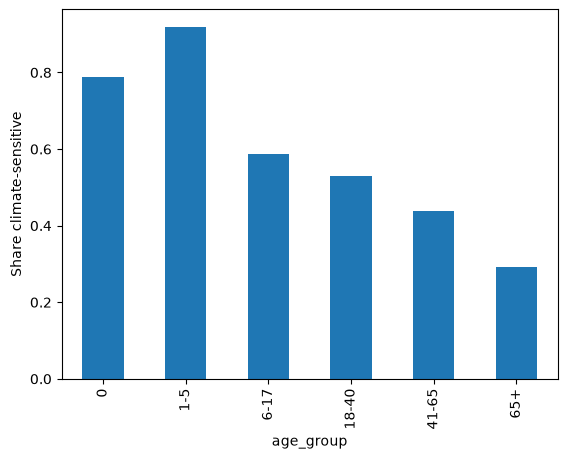

In [35]:
# Bar chart of class 1 share by age group, with readable labels

train['age_group'] = pd.cut(train['age'], bins=[-1, 0, 5, 17, 40, 65, 120], labels=['0', '1-5', '6-17', '18-40', '41-65', '65+'])
train.groupby('age_group', observed=True)['is_climate_sensitive'].mean().plot(kind='bar')
plt.ylabel('Share climate-sensitive')
plt.show()

**What it shows:** the share of deaths that are climate-sensitive within each age group.

**Pattern:** the share is highest at ages 1-5 (92%) and 0 (79%), then falls steadily with age: 59% at 6-17, 53% at 18-40, 44% at 41-65 and 29% at 65 and over.

**Meaning:** climate-sensitive deaths are concentrated in infants and young children, while deaths in older adults are mostly not climate-sensitive. Prevention work linked to climate would therefore focus first on young children. Age is expected to be the strongest predictor, but it does not decide the label alone: even at age 0, 21% of deaths are not climate-sensitive.

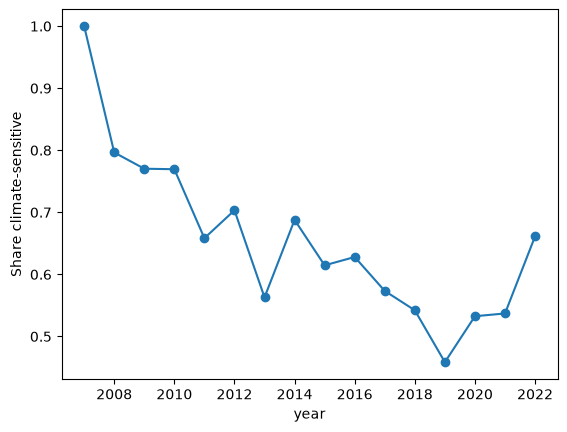

In [31]:
# Line chart of class 1 share by year
train.groupby('year')['is_climate_sensitive'].mean().plot(marker='o')
plt.ylabel('Share climate-sensitive')
plt.show()

**What it shows:** the share of deaths that are climate-sensitive in each year, 2007 to 2022.

**Pattern:** the share is about 77-80% in 2008-2010, then drifts down, reaching its lowest in 2019 (46%) and staying near 53-54% in 2020-2021. The 2007 and 2022 points rest on 1 and 62 deaths, so they are unreliable.

**Meaning:** the share of climate-sensitive deaths was clearly lower in recent years. Age mix does not explain this, since the recent years have younger deaths, which would push the share up. The data does not say why it fell, so no cause is claimed. The change could reflect real shifts or changes in how deaths were recorded.

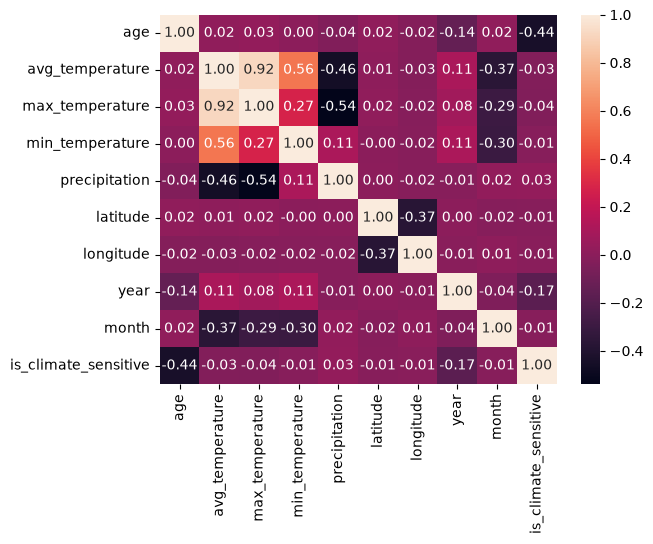

In [32]:
# Correlation heatmap of the numeric columns
import seaborn as sns
cols = ['age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'year', 'month', 'is_climate_sensitive']
sns.heatmap(train[cols].corr(), annot=True, fmt='.2f')
plt.show()

**What it shows:** the correlation between each pair of numeric columns, from -1 to 1. Values near 0 mean no straight-line relationship.

**Pattern:** age has the strongest link to the target (-0.44): older age goes with "not climate-sensitive". Year is weaker (-0.17). Temperature, precipitation, coordinates and month are all within 0.04 of zero. Among the inputs, average and maximum temperature are almost the same signal (0.92), precipitation moves against temperature (-0.46 to -0.54), and temperature follows the month (-0.29 to -0.37).

**Meaning:** the climate columns have no straight-line link to the label, which agrees with the near-identical class averages. Correlation only captures straight-line patterns, so it understates age (age 0 sits below ages 1-5) and cannot show the break after 2017. Models that can find such patterns will be tested. Average and maximum temperature repeat each other, which matters for linear models such as logistic regression.

## Business problem

Some deaths in a community are linked to climate conditions such as heat and rainfall, and some are not. This project builds a model that predicts whether a recorded death is climate-sensitive, using the person's age, the date, the location and local temperature and rainfall.

**Why it matters:** if we know which kinds of deaths are most often climate-sensitive, and when and where, health programmes can focus their prevention work on those groups and periods.

**Limits:** the model classifies deaths that have already been recorded. It does not forecast future deaths and it shows association, not cause.

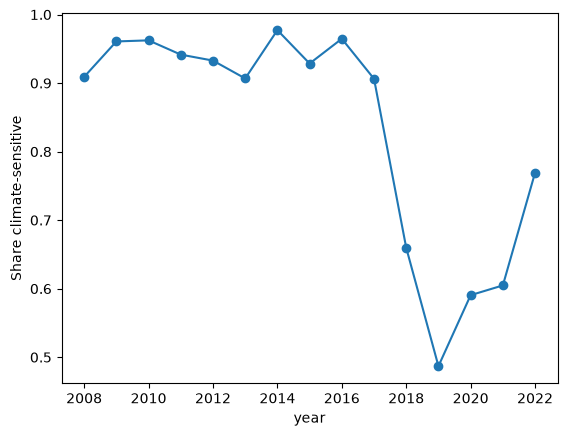

In [36]:
# Line chart of class 1 share by year for children aged 0 to 5
train[train['age'] <= 5].groupby('year')['is_climate_sensitive'].mean().plot(marker='o')
plt.ylabel('Share climate-sensitive')
plt.show()

**What it shows:** the share of climate-sensitive deaths in each year, for children aged 0 to 5 only. Restricting to this age group removes the effect of age.

**Pattern:** from 2008 to 2017 the share is steady at about 91-98%. In 2018 it falls to 66%, reaches its lowest in 2019 at 49%, and is about 59-60% in 2020 and 2021. It rises to 77% in 2022, but that year has only 52 deaths in this age group, so the rise is uncertain.

**Meaning:** for the same age group, the share of deaths labelled climate-sensitive changed sharply after 2017. This is not an age effect. The data does not explain it, so no cause is claimed. It could be a real change, or a change in how deaths were recorded or classified. For modelling, year (or a "2018 or later" flag) is expected to be an important feature, especially in combination with age. This break is also one of the more unusual features of this dataset, and it belongs in the write-up.